In [2]:
import numpy as np
from math import erf
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
%matplotlib inline

In [3]:
path = 'C:/Users/robtk/OneDrive/Desktop/3rd year Labs/Nuvistor Triode/'

In [4]:
R_A = 1.6
error_R_A = 0.022

In [5]:
# Defining equation of linear line of best fit 
def fitfunc(x, m, c):
    return x*m+c

In [6]:
def Schottky(V_R, T, I_AS):
    n_A = 1.602176565e-19 * V_R / (1.380649e-23 * T)
    IL_over_ILS = []
    for el in n_A:
        IL_over_ILS = np.append(IL_over_ILS, ( R_A * np.e**(el) * erf(-el/(R_A**2 - 1))**(1/2) + 1 - (erf(-el /(1 - 1/R_A**2)))**(1/2) ))
    
    return IL_over_ILS * I_AS

<ipython-input-60-8167e9731b75>:51: RuntimeWarning: invalid value encountered in log10
  pars, cov = curve_fit(fitfunc, V_A_circuit[Range[i]],  np.log10(-I_A/I_AS)[Range[i]], sigma = error_I_A[Range[i]])
<ipython-input-60-8167e9731b75>:51: RuntimeWarning: invalid value encountered in log10
  pars, cov = curve_fit(fitfunc, V_A_circuit[Range[i]],  np.log10(-I_A/I_AS)[Range[i]], sigma = error_I_A[Range[i]])
<ipython-input-60-8167e9731b75>:51: RuntimeWarning: invalid value encountered in log10
  pars, cov = curve_fit(fitfunc, V_A_circuit[Range[i]],  np.log10(-I_A/I_AS)[Range[i]], sigma = error_I_A[Range[i]])
<ipython-input-60-8167e9731b75>:51: RuntimeWarning: invalid value encountered in log10
  pars, cov = curve_fit(fitfunc, V_A_circuit[Range[i]],  np.log10(-I_A/I_AS)[Range[i]], sigma = error_I_A[Range[i]])


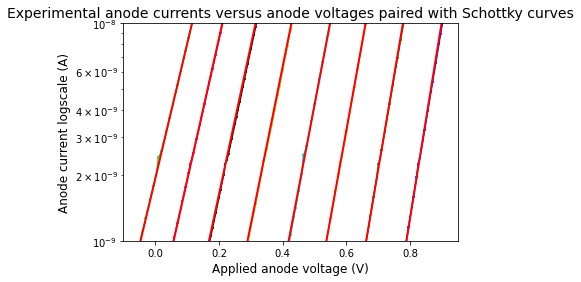

In [60]:
# Creating the Schottky curves and translating them to coincide with the experimental data

# Set filament currents to access the data
I_F = [65.0, 70.0, 75.0, 80.0, 85.0, 90, 95.0, 100.0]

# I_AS was found through inspection as being the current associated with the following applied voltages for each I_F.
experimental_V_AS = np.array([1.08, 1.03, 1.035, 1.03, 1.05, .97, 1.260, 1.980])

# Define the range on which the slope of the log10(I_A/I_AS) graph is spliced in order to calculate the electron temperature.
Range = [np.arange(225,275,1), np.arange(290,351,1), np.arange(250,351,1), np.arange(250,351,1), 
         np.arange(250,351,1), np.arange(200,301,1), np.arange(200,326,1), np.arange(200,301,1)]

# How much to translate the theoretical Schottky curve by to coincide with experiment for each I_F value
translate = [1.0229, 0.9995, 0.9884, 0.9799, 0.9645, 0.9491, 0.9507, 0.9625]

#plt.figure(figsize = (9, 9))

colours = ["b", "g", "orange", "c", "y", "k", "m", "limegreen"]

# Values needed to define error_I_A
Ranges = ["Range=002nA", "Range=020nA", "Range=200nA", "Range=002uA", "Range=020uA", "Range=200uA", "Range=002mA"]
error_values = [5e-14, 5e-13, 5e-12, 5e-11, 5e-10, 5e-9, 5e-8]


i = 0
while i < len(I_F):
    # Load in data.
    I_A =          np.load(path+f"anode currents for I_F {I_F[i]} mA.npy")
    V_A_circuit =  np.load(path+f"anode voltages for I_F {I_F[i]} mA.npy")
    alloutputs =   np.load(path+f"alloutputs for I_F {I_F[i]} mA.npy")
    error_I_A =    np.load(path+f"anode currents errors for I_F {I_F[i]} mA.npy")
    
    #Define error_I_A correctly
    
    h = 0
    while h < len(Ranges):    
        k = 0
        while k < len(I_A):
            if alloutputs[k*4+1] == Ranges[h]:
                error_I_A[k] = error_values[h]
            k += 1
        h += 1
        
    # Define the index of where the saturated anode current is in the I_A array for each I_F.
    index = np.where(np.isclose(V_A_circuit, experimental_V_AS[i]))
    
    # Get saturated anode current and its error for each I_F.
    I_AS = -I_A[index]
    error_I_AS = error_I_A[np.where(-I_A == I_AS)]

    
    # Compute T and its error for each I_F.
    pars, cov = curve_fit(fitfunc, V_A_circuit[Range[i]],  np.log10(-I_A/I_AS)[Range[i]], sigma = error_I_A[Range[i]])
    T = 5040/pars[0]
    error_on_slope = np.sqrt(cov[0,0])
    error_T = np.sqrt((-5040/pars[0]**2)**2 * error_on_slope**2)
    
    # Plot experimental data.
    plt.errorbar(V_A_circuit, (-I_A), error_I_A, 3.5e-3, fmt = "", color = colours[i], 
                 zorder = 1, label = f"experimental data for $I_F = {I_F[i]} mA")
    
    # Set x-axis for theoretical data.
    V_R = np.append(np.arange(-2,0,0.01), np.array([0]))

    # plot the Schottky curve and translate it so the slope coincides with the slope of the experimental data.
    plt.plot(V_R + translate[i], Schottky(V_R, T, I_AS), "r", linewidth = "2", zorder = 2)
    
    # The horizontal line at V_R = 0 is plotted to complete the Schottky curve.
    plt.plot(np.linspace(0,1,3) + translate[i], np.zeros(3) + Schottky(np.array([0]), T, I_AS),
             "r", linewidth = "2", zorder = 2);
    
    i += 1

# For entire plot
#plt.ylim(10e-13,10e-3)

# For zooming in
plt.ylim(10e-10, 10e-9)
plt.xlim(-0.1, 0.95);

plt.yscale("log")
plt.title("Experimental anode currents versus anode voltages paired with Schottky curves", fontsize = 14)
plt.ylabel("Anode current logscale (A)", fontsize = 12)
plt.xlabel("Applied anode voltage (V)", fontsize = 12)
#plt.legend()
plt.savefig("All Schottky curves half zoomed in", dpi = 100, bbox_inches = "tight");